In [2]:
# Install dependencies if needed:
# %pip install snowflake
# %pip install boto3
# %pip install python-dotenv snowflake-connector-python

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [ ]:
import os
import snowflake.connector
import getpass
import botocore
import boto3
from dotenv import load_dotenv

# Load credentials from local .env file
load_dotenv()

USER = os.getenv("SNOWFLAKE_USER")
ACCOUNT = os.getenv("SNOWFLAKE_ACCOUNT")
PASSWORD = os.getenv("SNOWFLAKE_PASSWORD")

# Prompt for MFA code each time you connect
AUTH = input("Enter MFA code: ")

try:
    conn = snowflake.connector.connect(
        user=USER,
        password=PASSWORD,
        account=ACCOUNT,
        authenticator="USERNAME_PASSWORD_MFA",
        passcode=AUTH
    )

    print("Successfully connected to Snowflake!")

except Exception as e:
    print("Connection failed:", e)

Enter MFA code:  244383


Connection failed: 000007: Configuration error: Configuration validation failed (4 issue(s)): account: Missing required parameter 'account'; user: Missing required parameter 'user'; password: Missing required parameter 'password' for MFA authentication; host: Missing required parameter 'host' (or 'server_url')


C:\Users\student\anaconda3\Lib\site-packages\snowflake\connector\connection\_connection.py:137: FutureWarning: enable_server_session_keep_alive_auto_detection was not set and defaults to True. In a future version, the default will change to None. Please provide an explicit value: True = check for running async queries before logout (queries are preserved); False/None = always send logout on close (async queries may be terminated by server). Logout behavior can also be overridden with server_session_keep_alive. See the connection parameter docs for more info.
  options = self.config.to_proto_options(


# Average Weekly Sales

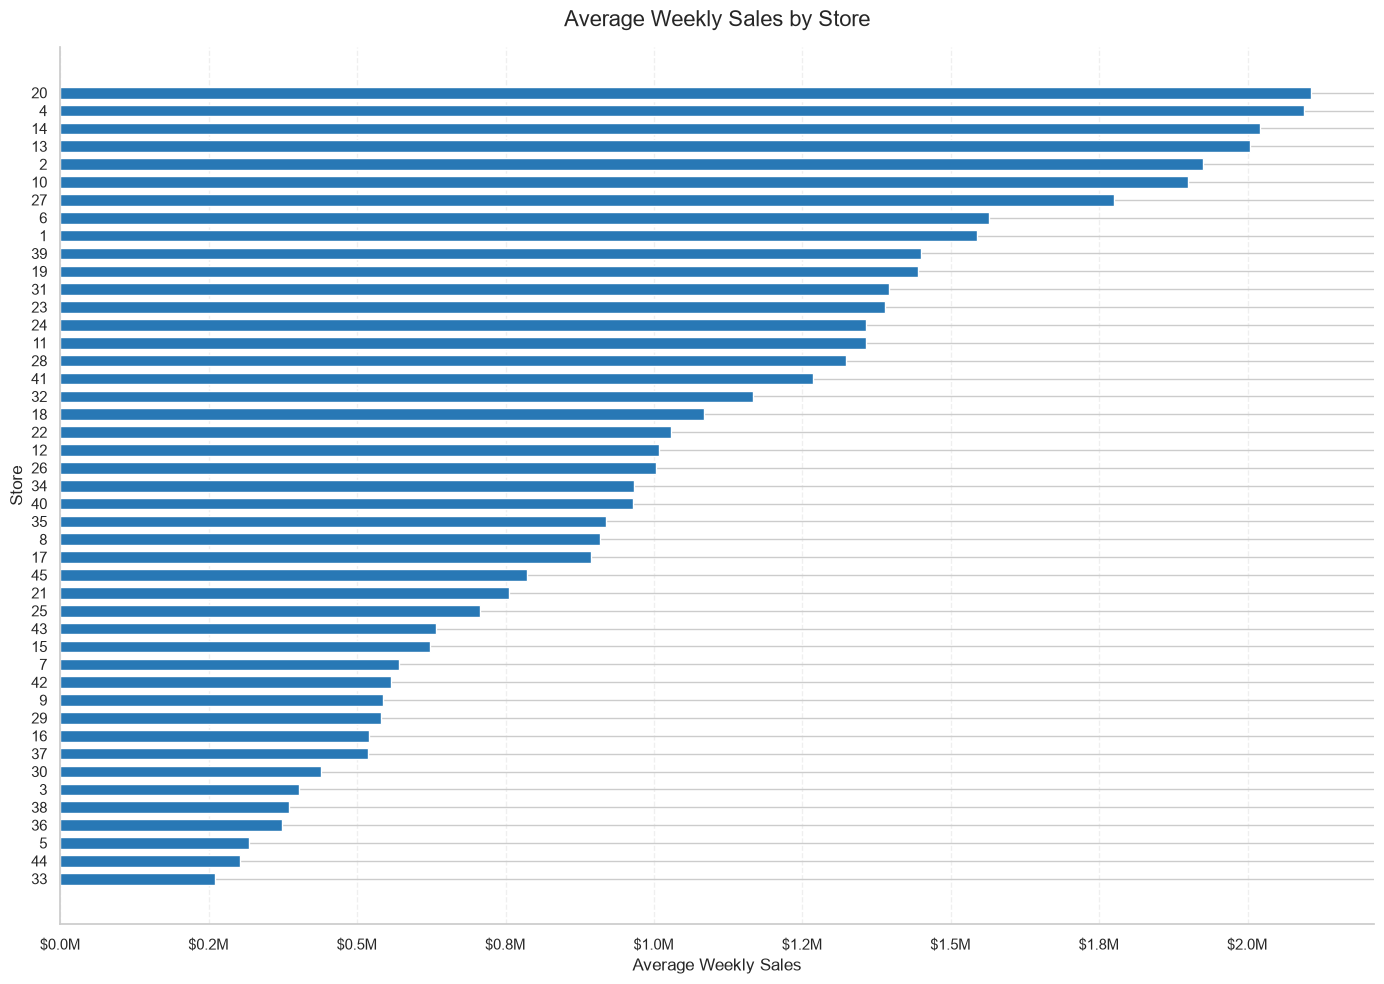

True

In [4]:
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import botocore
import boto3
# from snowflake_connector import conn

# .venv needs to be created in your folder before running this Python script

# Create a cursor object to execute SQL queries
cur = conn.cursor()

# Execute a SQL query to retrieve data from the DATE_DIM table
sql = """WITH WEEKLY_STORE_SALES AS (
    SELECT
        STORE_ID,
        DATE_ID,
        SUM(STORE_WEEKLY_SALES) AS TOTAL_WEEKLY_SALES
    FROM WALMART_DB.SNAPSHOTS.FACT_SNAPSHOT
    GROUP BY STORE_ID, DATE_ID
),

AVERAGE_STORE_SALES AS (
    SELECT
        STORE_ID,
        AVG(TOTAL_WEEKLY_SALES) AS AVG_WEEKLY_SALES
    FROM WEEKLY_STORE_SALES
    GROUP BY STORE_ID
)

SELECT
    STORE_ID,
    AVG_WEEKLY_SALES
FROM AVERAGE_STORE_SALES
ORDER BY AVG_WEEKLY_SALES DESC;"""

cur.execute(sql)

# Fetch the results set from the cursor and deliver it as a pandas DataFrame
df = cur.fetch_pandas_all()

# Prepare data for visualization
df["STORE_ID"] = df["STORE_ID"].astype(str)
df = df.sort_values("AVG_WEEKLY_SALES", ascending=True)

# Create horizontal bar chart
fig, ax = plt.subplots(figsize=(14, 10))

ax.barh(
    df["STORE_ID"],
    df["AVG_WEEKLY_SALES"],
    color="#2878B5",
    height=0.65
)

# Format chart title and axes
ax.set_title(
    "Average Weekly Sales by Store",
    fontsize=16,
    pad=15
)

ax.set_xlabel("Average Weekly Sales", fontsize=12)
ax.set_ylabel("Store", fontsize=12)

# Format x-axis in millions
ax.xaxis.set_major_formatter(
    mticker.FuncFormatter(lambda x, _: f"${x / 1_000_000:.1f}M")
)

# Improve chart appearance
ax.grid(axis="x", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

# Close cursor
cur.close()

# SQL Select specific columns and print the first values from each (i.e., first row).
# col1, col2 = conn.cursor().execute("SELECT DATE_ID, IS_HOLIDAY FROM WALMART_DB.GOLD.DATE_DIM").fetchone()
# print('{0}, {1}'.format(col1, col2))

# SQL Select specific columns and print the first 100 values from each (i.e., first 100 rows) using for loop.
# for (col1, col2) in conn.cursor().execute("SELECT DATE_ID, IS_HOLIDAY FROM WALMART_DB.GOLD.DATE_DIM LIMIT 100"):
#     print('{0}, {1}'.format(col1, col2))

# conn.close()

# Holiday vs Non-Holiday Sales

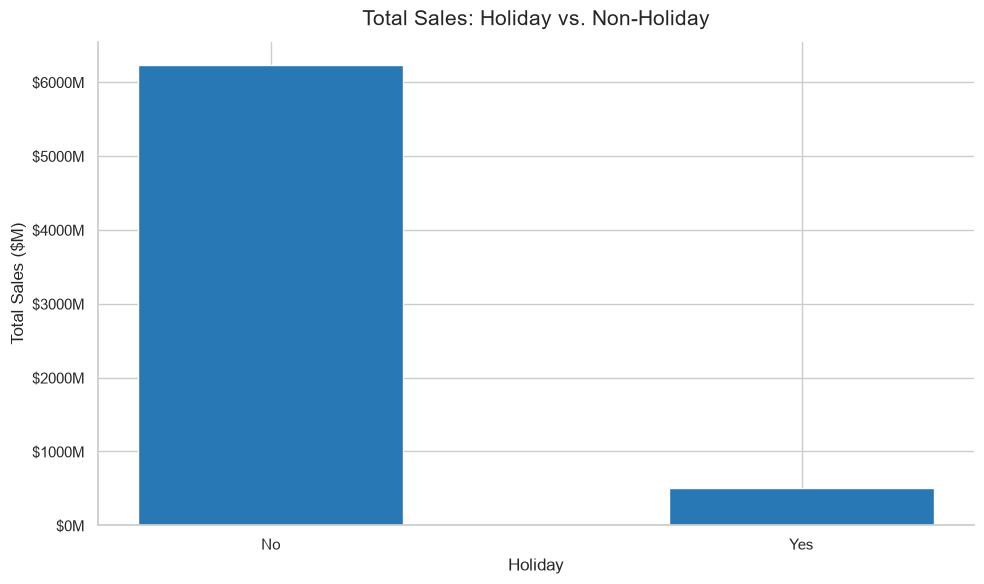

True

In [5]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import pandas as pd

# Create cursor
cur = conn.cursor()

# SQL query
sql = """
SELECT
    D.IS_HOLIDAY,
    SUM(F.STORE_WEEKLY_SALES) AS TOTAL_SALES
FROM WALMART_DB.SNAPSHOTS.FACT_SNAPSHOT F

INNER JOIN WALMART_DB.GOLD.DATE_DIM D
    ON F.DATE_ID = D.DATE_ID

GROUP BY
    D.IS_HOLIDAY

ORDER BY
    D.IS_HOLIDAY;
"""

# Execute query
cur.execute(sql)

# Retrieve results
df = cur.fetch_pandas_all()

# Ensure holiday categories appear in desired order
df["IS_HOLIDAY"] = pd.Categorical(
    df["IS_HOLIDAY"],
    categories=["No", "Yes"],
    ordered=True
)

df = df.sort_values("IS_HOLIDAY")

# Create bar chart
fig, ax = plt.subplots(figsize=(10, 6))

ax.bar(
    df["IS_HOLIDAY"].astype(str),
    df["TOTAL_SALES"],
    color="#2878B5",
    width=0.5
)

# Chart title and labels
ax.set_title(
    "Total Sales: Holiday vs. Non-Holiday",
    fontsize=15,
    pad=12
)

ax.set_xlabel("Holiday", fontsize=12)
ax.set_ylabel("Total Sales ($M)", fontsize=12)

# Format y-axis in millions
ax.yaxis.set_major_formatter(
    mticker.FuncFormatter(
        lambda x, _: f"${x / 1_000_000:.0f}M"
    )
)

# Clean up chart appearance
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

# Close cursor
cur.close()

# Annual Total Sales

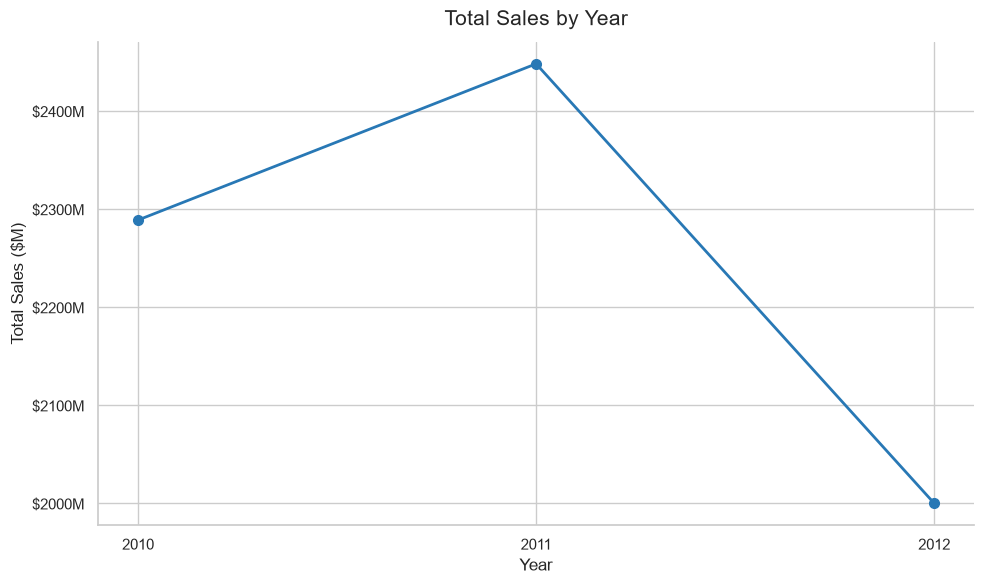

True

In [7]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import pandas as pd

# Create cursor
cur = conn.cursor()

# SQL query
sql = """
SELECT
    YEAR(D.STORE_DATE) AS SALES_YEAR,
    SUM(F.STORE_WEEKLY_SALES) AS TOTAL_SALES
FROM WALMART_DB.SNAPSHOTS.FACT_SNAPSHOT F

INNER JOIN WALMART_DB.GOLD.DATE_DIM D
    ON F.DATE_ID = D.DATE_ID

GROUP BY
    YEAR(D.STORE_DATE)

HAVING
    SALES_YEAR <> 2026

ORDER BY
    SALES_YEAR;
"""

# Execute query
cur.execute(sql)

# Retrieve results
df = cur.fetch_pandas_all()

# Ensure chronological ordering
df = df.sort_values("SALES_YEAR")

# Create line chart
fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(
    df["SALES_YEAR"],
    df["TOTAL_SALES"],
    marker="o",
    markersize=7,
    linewidth=2,
    color="#2878B5"
)

# Chart title and labels
ax.set_title(
    "Total Sales by Year",
    fontsize=15,
    pad=12
)

ax.set_xlabel("Year", fontsize=12)
ax.set_ylabel("Total Sales ($M)", fontsize=12)

# Format y-axis in millions
ax.yaxis.set_major_formatter(
    mticker.FuncFormatter(
        lambda x, _: f"${x / 1_000_000:.0f}M"
    )
)

# Display each year as a tick
ax.set_xticks(df["SALES_YEAR"])

# Clean up chart appearance
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

# Close cursor
cur.close()

# Sales by Store Type

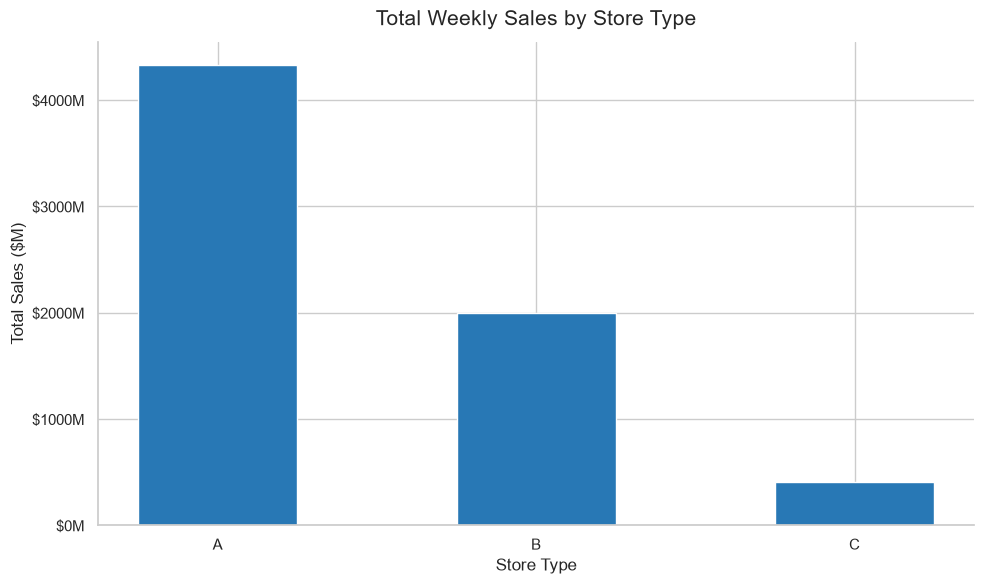

True

In [8]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import pandas as pd

# Create cursor
cur = conn.cursor()

# SQL query
sql = """
WITH STORE_SALES AS (
    SELECT
        STORE_ID,
        SUM(STORE_WEEKLY_SALES) AS TOTAL_WEEKLY_SALES
    FROM WALMART_DB.SNAPSHOTS.FACT_SNAPSHOT
    GROUP BY STORE_ID
),

STORE_TYPES AS (
    SELECT DISTINCT
        STORE_ID,
        STORE_TYPE
    FROM WALMART_DB.GOLD.STORE_DEPT_DIM
)

SELECT
    T.STORE_TYPE,
    SUM(S.TOTAL_WEEKLY_SALES) AS TOTAL_SALES
FROM STORE_SALES S

INNER JOIN STORE_TYPES T
    ON S.STORE_ID = T.STORE_ID

GROUP BY
    T.STORE_TYPE

ORDER BY
    T.STORE_TYPE;
"""

# Execute query
cur.execute(sql)

# Retrieve results
df = cur.fetch_pandas_all()

# Ensure store types are sorted
df = df.sort_values("STORE_TYPE")

# Create bar chart
fig, ax = plt.subplots(figsize=(10, 6))

ax.bar(
    df["STORE_TYPE"].astype(str),
    df["TOTAL_SALES"],
    color="#2878B5",
    width=0.5
)

# Chart title and labels
ax.set_title(
    "Total Weekly Sales by Store Type",
    fontsize=15,
    pad=12
)

ax.set_xlabel("Store Type", fontsize=12)
ax.set_ylabel("Total Sales ($M)", fontsize=12)

# Format y-axis in millions
ax.yaxis.set_major_formatter(
    mticker.FuncFormatter(
        lambda x, _: f"${x / 1_000_000:.0f}M"
    )
)

# Clean up chart appearance
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

# Close cursor
cur.close()

# Weekly Sales by Store Type Over Time

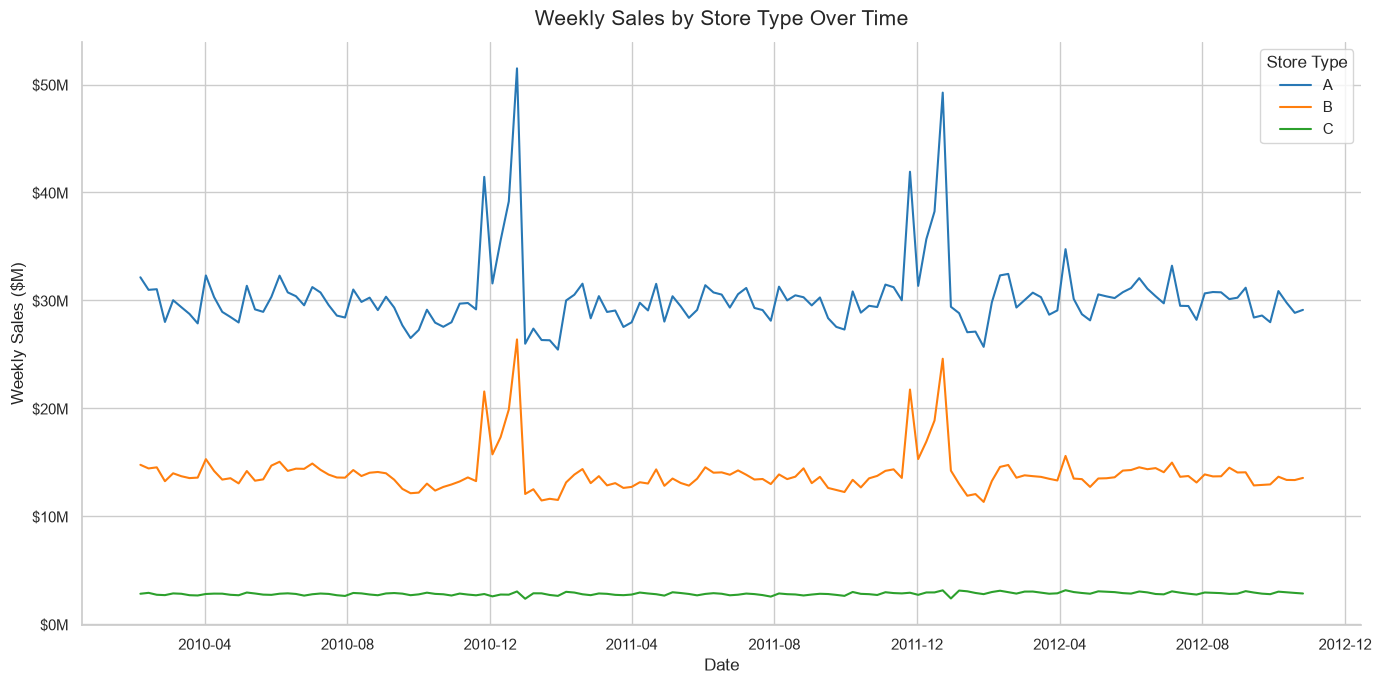

True

In [10]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as mticker
import pandas as pd

# Create cursor
cur = conn.cursor()

# SQL query
sql = """
WITH STORE_WEEKLY_SALES AS (
    SELECT
        STORE_ID,
        DATE_ID,
        SUM(STORE_WEEKLY_SALES) AS WEEKLY_SALES
    FROM WALMART_DB.SNAPSHOTS.FACT_SNAPSHOT
    GROUP BY STORE_ID, DATE_ID
),

STORE_TYPES AS (
    SELECT DISTINCT
        STORE_ID,
        STORE_TYPE
    FROM WALMART_DB.GOLD.STORE_DEPT_DIM
)

SELECT
    D.STORE_DATE,
    T.STORE_TYPE,
    SUM(S.WEEKLY_SALES) AS TOTAL_WEEKLY_SALES
FROM STORE_WEEKLY_SALES S

INNER JOIN STORE_TYPES T
    ON S.STORE_ID = T.STORE_ID

INNER JOIN WALMART_DB.GOLD.DATE_DIM D
    ON S.DATE_ID = D.DATE_ID

WHERE YEAR(D.STORE_DATE) < 2026

GROUP BY
    D.STORE_DATE,
    T.STORE_TYPE

ORDER BY
    D.STORE_DATE,
    T.STORE_TYPE;
"""

# Execute query
cur.execute(sql)

# Retrieve results
df = cur.fetch_pandas_all()

# Convert dates to datetime
df["STORE_DATE"] = pd.to_datetime(df["STORE_DATE"])

# Sort data chronologically
df = df.sort_values("STORE_DATE")

# Create line chart
fig, ax = plt.subplots(figsize=(14, 7))

# Define colors for each store type
colors = {
    "A": "#2878B5",
    "B": "#FF7F0E",
    "C": "#2CA02C"
}

# Plot a separate line for each store type
for store_type in ["A", "B", "C"]:

    store_data = df[df["STORE_TYPE"] == store_type]

    ax.plot(
        store_data["STORE_DATE"],
        store_data["TOTAL_WEEKLY_SALES"],
        label=store_type,
        color=colors[store_type],
        linewidth=1.5
    )

# Chart title and labels
ax.set_title(
    "Weekly Sales by Store Type Over Time",
    fontsize=15,
    pad=12
)

ax.set_xlabel("Date", fontsize=12)
ax.set_ylabel("Weekly Sales ($M)", fontsize=12)

# Format y-axis in millions
ax.yaxis.set_major_formatter(
    mticker.FuncFormatter(
        lambda x, _: f"${x / 1_000_000:.0f}M"
    )
)

# Format x-axis dates
ax.xaxis.set_major_locator(
    mdates.MonthLocator(interval=4)
)

ax.xaxis.set_major_formatter(
    mdates.DateFormatter("%Y-%m")
)

# Rotate date labels if necessary
plt.xticks(rotation=0)

# Add legend
ax.legend(
    title="Store Type",
    loc="upper right"
)

# Clean up chart appearance
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

# Close cursor
cur.close()

# Average Weekly Sales vs. Store Size

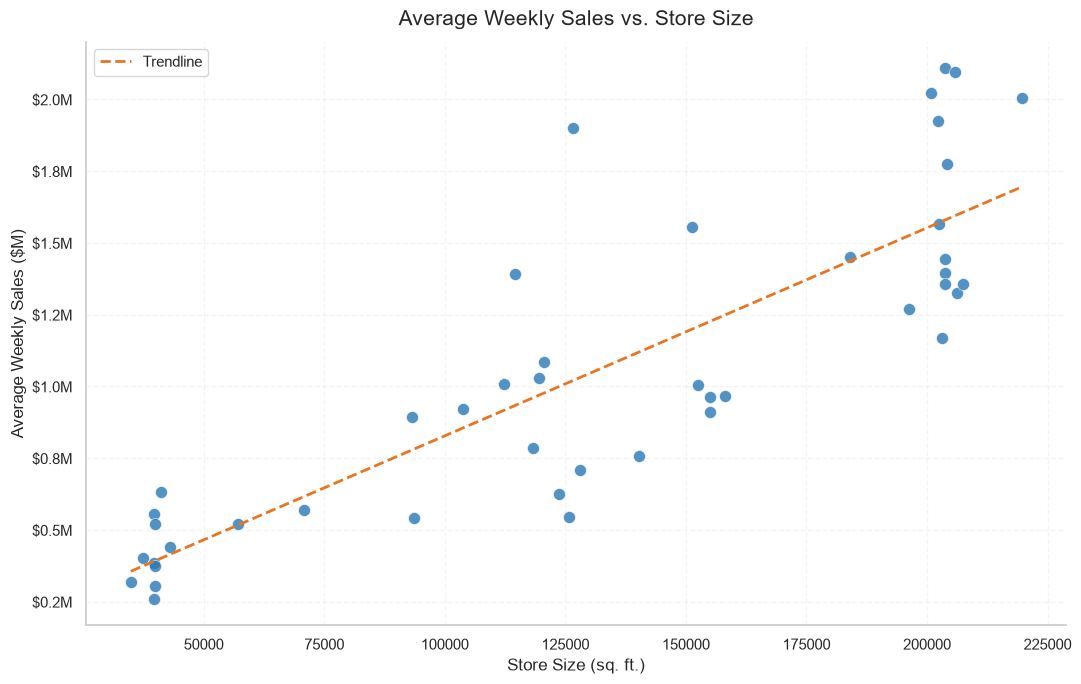

True

In [12]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd

# Create cursor
cur = conn.cursor()

# SQL query
sql = """
WITH STORE_WEEKLY_SALES AS (
    SELECT
        F.STORE_ID,
        F.DATE_ID,
        SUM(F.STORE_WEEKLY_SALES) AS WEEKLY_SALES
    FROM WALMART_DB.SNAPSHOTS.FACT_SNAPSHOT F

    INNER JOIN WALMART_DB.GOLD.DATE_DIM D
        ON F.DATE_ID = D.DATE_ID

    WHERE YEAR(D.STORE_DATE) < 2026

    GROUP BY
        F.STORE_ID,
        F.DATE_ID
),

AVERAGE_STORE_SALES AS (
    SELECT
        STORE_ID,
        AVG(WEEKLY_SALES) AS AVG_WEEKLY_SALES
    FROM STORE_WEEKLY_SALES
    GROUP BY STORE_ID
),

STORE_INFO AS (
    SELECT
        STORE_ID,
        MAX(STORE_SIZE) AS STORE_SIZE
    FROM WALMART_DB.GOLD.STORE_DEPT_DIM
    GROUP BY STORE_ID
    HAVING COUNT(DISTINCT STORE_SIZE) = 1
)

SELECT
    S.STORE_ID,
    I.STORE_SIZE,
    S.AVG_WEEKLY_SALES
FROM AVERAGE_STORE_SALES S

INNER JOIN STORE_INFO I
    ON S.STORE_ID = I.STORE_ID

ORDER BY I.STORE_SIZE;
"""

# Execute query
cur.execute(sql)

# Retrieve results
df = cur.fetch_pandas_all()

# Create scatter plot
fig, ax = plt.subplots(figsize=(11, 7))

ax.scatter(
    df["STORE_SIZE"],
    df["AVG_WEEKLY_SALES"],
    color="#2878B5",
    s=75,
    alpha=0.8,
    edgecolors="white",
    linewidths=0.5
)

# Convert Snowflake Decimal values to floats
x = df["STORE_SIZE"].astype(float).to_numpy()
y = df["AVG_WEEKLY_SALES"].astype(float).to_numpy()

# Calculate linear trendline
slope, intercept = np.polyfit(x, y, 1)

trendline = slope * x + intercept

ax.plot(
    x,
    trendline,
    color="#E87522",
    linewidth=2,
    linestyle="--",
    label="Trendline"
)

# Chart title and labels
ax.set_title(
    "Average Weekly Sales vs. Store Size",
    fontsize=15,
    pad=12
)

ax.set_xlabel("Store Size (sq. ft.)", fontsize=12)
ax.set_ylabel("Average Weekly Sales ($M)", fontsize=12)

# Format y-axis in millions
ax.yaxis.set_major_formatter(
    mticker.FuncFormatter(
        lambda value, _: f"${value / 1_000_000:.1f}M"
    )
)

# Add legend
ax.legend()

# Clean up chart appearance
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.grid(axis="both", linestyle="--", alpha=0.2)

plt.tight_layout()
plt.show()

# Close cursor
cur.close()

# Average Weekly Sales vs Temperature

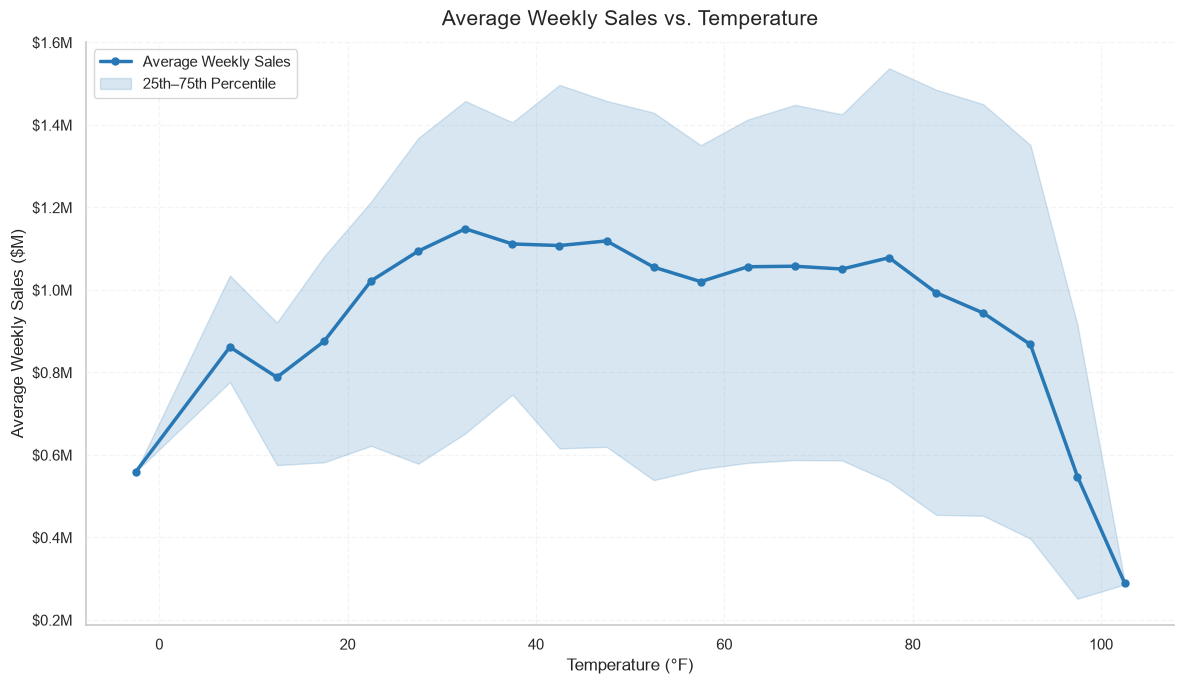

True

In [13]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd

# Create cursor
cur = conn.cursor()

# SQL query
sql = """
WITH STORE_WEEKLY_SALES AS (
    SELECT
        F.STORE_ID,
        F.DATE_ID,
        SUM(F.STORE_WEEKLY_SALES) AS WEEKLY_SALES,
        AVG(F.STORE_TEMPERATURE) AS TEMPERATURE
    FROM WALMART_DB.SNAPSHOTS.FACT_SNAPSHOT F

    INNER JOIN WALMART_DB.GOLD.DATE_DIM D
        ON F.DATE_ID = D.DATE_ID

    WHERE YEAR(D.STORE_DATE) < 2026

    GROUP BY
        F.STORE_ID,
        F.DATE_ID
)

SELECT
    TEMPERATURE,
    WEEKLY_SALES
FROM STORE_WEEKLY_SALES
WHERE TEMPERATURE IS NOT NULL
ORDER BY TEMPERATURE;
"""

# Execute query
cur.execute(sql)

# Retrieve results
df = cur.fetch_pandas_all()

# Convert Snowflake Decimal values to floats
df["TEMPERATURE"] = df["TEMPERATURE"].astype(float)
df["WEEKLY_SALES"] = df["WEEKLY_SALES"].astype(float)

# Remove missing values
df = df.dropna(subset=["TEMPERATURE", "WEEKLY_SALES"])

# Group temperatures into 5-degree intervals
df["TEMP_BIN"] = np.floor(df["TEMPERATURE"] / 5) * 5

# Calculate average and sales distribution
summary = (
    df.groupby("TEMP_BIN")
    .agg(
        AVG_SALES=("WEEKLY_SALES", "mean"),
        LOWER_RANGE=("WEEKLY_SALES",
                     lambda x: x.quantile(0.25)),
        UPPER_RANGE=("WEEKLY_SALES",
                     lambda x: x.quantile(0.75)),
        OBSERVATIONS=("WEEKLY_SALES", "count")
    )
    .reset_index()
)

# Use midpoint of each temperature interval
summary["TEMP_MIDPOINT"] = summary["TEMP_BIN"] + 2.5

# Create visualization
fig, ax = plt.subplots(figsize=(12, 7))

# Plot average weekly sales
ax.plot(
    summary["TEMP_MIDPOINT"],
    summary["AVG_SALES"],
    color="#2878B5",
    linewidth=2.5,
    marker="o",
    markersize=5,
    label="Average Weekly Sales"
)

# Add shaded distribution range
ax.fill_between(
    summary["TEMP_MIDPOINT"],
    summary["LOWER_RANGE"],
    summary["UPPER_RANGE"],
    color="#2878B5",
    alpha=0.18,
    label="25th–75th Percentile"
)

# Chart title and labels
ax.set_title(
    "Average Weekly Sales vs. Temperature",
    fontsize=15,
    pad=12
)

ax.set_xlabel("Temperature (°F)", fontsize=12)
ax.set_ylabel("Average Weekly Sales ($M)", fontsize=12)

# Format y-axis in millions
ax.yaxis.set_major_formatter(
    mticker.FuncFormatter(
        lambda x, _: f"${x / 1_000_000:.1f}M"
    )
)

# Add legend
ax.legend(loc="upper left")

# Clean up chart appearance
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.grid(axis="both", linestyle="--", alpha=0.2)

plt.tight_layout()
plt.show()

# Close cursor
cur.close()